<a href="https://colab.research.google.com/github/Violetaaa/tfg-learning/blob/main/04_gis_with_python/04_crs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6.4 Sistemas de coordenadas de referencia (CRS) (resumen)

Resumen del capítulo *Working with map projections* de *Python for Geographic Data Analysis* (Tenkanen et al., pythongis.org), reducido a lo que se usa en el TFG.

El libro usa mapas de Europa y del mundo. Aquí se usan tus capas de Asturias.

**Ideas clave**
- El CRS indica qué significan los números de las coordenadas: grados sobre el elipsoide (geográfico) o metros sobre un plano (proyectado).
- Se identifica con un código **EPSG**. GeoPandas lo guarda en `gdf.crs`, que es un objeto `pyproj.CRS`.
- Los CRS del TFG:

| EPSG | Nombre | Unidades | Dónde aparece |
|---|---|---|---|
| 4326 | WGS 84 | grados | capas del SIG de Asturias, OSM, GPS |
| 4258 | ETRS89 | grados | capas del MITECO |
| **25830** | **ETRS89 / UTM 30N** | **metros** | **CRS de trabajo del TFG** |

- WGS 84 y ETRS89 difieren menos de un metro en España, pero GeoPandas los trata como CRS distintos.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
from pyproj import CRS

# Folder that contains raw/ and asturias_miteco.gpkg. In Colab, e.g. Path("/content/drive/MyDrive/tfg/datos").
DATA_DIR = Path("/content/drive/MyDrive/tfg/")
CRS_METRES = "EPSG:25830"

municipalities = gpd.read_file(DATA_DIR / "miteco_data/out/asturias_miteco.gpkg")
pharmacies = gpd.read_file(sorted(DATA_DIR.glob("sitpa_raw_data/farmacias_botiquines__farmacias_*.geojson"))[-1])

print("municipalities:", municipalities.crs)
print("pharmacies:    ", pharmacies.crs)

municipalities: EPSG:4258
pharmacies:     EPSG:4326


Tus dos capas vienen en CRS distintos. Antes de combinarlas, por ejemplo con un *spatial join* de farmacias dentro de concejos, **hay que llevarlas al mismo CRS**. Si no, GeoPandas avisa y el resultado no es fiable.

## Inspeccionar un CRS
Aunque falte el código EPSG, el valor de las coordenadas ya da una pista: valores entre −180 y 180 son grados; valores de cientos de miles o millones son metros.

In [3]:
crs = CRS.from_user_input(CRS_METRES)

print("Name:     ", crs.name)
print("Projected:", crs.is_projected)
print("Units:    ", crs.axis_info[0].unit_name)
print("Area of use:", crs.area_of_use.name)
print("EPSG:     ", municipalities.crs.to_epsg())  # get the code back from a layer's CRS

Name:      ETRS89 / UTM zone 30N
Projected: True
Units:     metre
Area of use: Europe between 6°W and 0°W: Faroe Islands offshore; Ireland - offshore; Jan Mayen - offshore; Norway including Svalbard - offshore; Spain - mainland - onshore and offshore.
EPSG:      4258


## Reproyectar: `to_crs`
`to_crs` **transforma las coordenadas** a otro CRS y devuelve un GeoDataFrame nuevo, así que hay que asignar el resultado. Es lo que harás al cargar cualquier capa en el TFG.

In [4]:
municipalities_m = municipalities.to_crs(CRS_METRES)
pharmacies_m = pharmacies.to_crs(CRS_METRES)

print(pharmacies.geometry.iloc[0])    # degrees
print(pharmacies_m.geometry.iloc[0])  # metres
print(pharmacies_m.crs == municipalities_m.crs)  # now both layers can be combined

POINT (-5.922250437878334 43.555858307431485)
POINT (263965.2266968355 4826694.399595341)
True


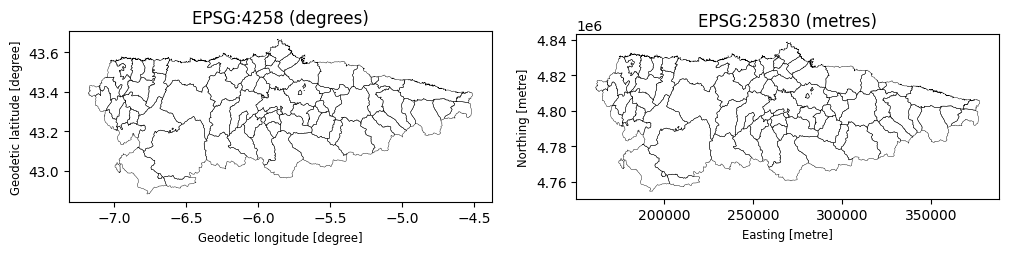

In [5]:
# Same data, two CRS: in degrees Asturias looks horizontally stretched
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 3))
municipalities.plot(ax=ax1, facecolor="none", linewidth=0.3)
municipalities_m.plot(ax=ax2, facecolor="none", linewidth=0.3)
ax1.set_title("EPSG:4258 (degrees)")
ax2.set_title("EPSG:25830 (metres)");

## Asignar un CRS: `set_crs` (¡no confundir con `to_crs`!)
`set_crs` **no cambia las coordenadas**: solo declara en qué CRS ya están. Se usa cuando la capa no tiene CRS, por ejemplo al crearla desde un CSV con `points_from_xy`.

| | Cambia los números | Cuándo se usa |
|---|---|---|
| `to_crs` | sí | la capa tiene CRS y quieres otro |
| `set_crs` | no | la capa no tiene CRS (`crs is None`) y sabes cuál es |

Usar `set_crs` para «convertir» es un error silencioso: las coordenadas en grados quedan etiquetadas como metros y todo cae cerca de (0, 0).

In [ ]:
from shapely import Point

no_crs = gpd.GeoDataFrame(geometry=[Point(-5.8448, 43.3614)])  # Oviedo, lon/lat but no CRS declared
print(no_crs.crs)                                              # None

right = no_crs.set_crs("EPSG:4326").to_crs(CRS_METRES)  # declare, then transform
wrong = no_crs.set_crs(CRS_METRES)                      # labels degrees as metres

print("right:", right.geometry.iloc[0])
print("wrong:", wrong.geometry.iloc[0], "<- a point about 44 m from (0, 0), not in Asturias")

None
right: POINT (269483.09189181624 4804879.797331161)
wrong: POINT (-5.8448 43.3614) <- a point about 44 m from (0, 0), not in Asturias


## ¿Vale EPSG:25830 para toda Asturias?
Según su área de uso oficial (celda anterior), UTM 30N cubre de 6° O a 0°. **El occidente de Asturias, al oeste de 6° O (del Navia al Eo), cae en la zona 29.** Fuera de su zona, la proyección distorsiona algo más. La celda siguiente mide cuánto, con el factor de escala: 1 significa sin error, y 1,001 significa 1 m de error por cada km.

In [ ]:
from pyproj import Proj

utm30 = Proj(CRS_METRES)
for lon in [-7.18, -6.0, -4.51]:  # west edge, zone limit, east edge of Asturias
    k = utm30.get_factors(lon, 43.3).meridional_scale
    print(f"lon {lon:6.2f}: scale factor {k:.5f} -> {abs(k - 1) * 1000:.1f} m error per km")

lon  -7.18: scale factor 1.00101 -> 1.0 m error per km
lon  -6.00: scale factor 1.00033 -> 0.3 m error per km
lon  -4.51: scale factor 0.99978 -> 0.2 m error per km


En el peor caso, el extremo occidental, el error es de unos 1 m por km (0,1 %): un buffer de 5 km queda desviado unos 5 m. Para preguntas sobre acceso a servicios es despreciable, así que usar un solo CRS para toda la región es razonable. Si lo justificas en la memoria, cita este cálculo y la definición EPSG de 25830 como fuente, no lo afirmes sin respaldo.

## Lo que se ha omitido del capítulo
- **Proyecciones globales** (Web Mercator `3857`, Eckert IV, ortográfica): solo para mapas del mundo. `3857` es la que usan los mapas web; **nunca midas en ella**, porque exagera las distancias (en Asturias, alrededor de un 37 %).
- **Exportar el CRS a WKT o PROJ** (`crs.to_wkt()`) y `to_epsg(min_confidence=...)`: útiles si un fichero trae un CRS raro sin código EPSG.
- **Guardar con el CRS en el nombre** del fichero: buena costumbre. En tu flujo, los GeoPackage de `processed/` van todos en 25830.

Documentación: https://geopandas.org/en/stable/docs/user_guide/projections.html